# ABA · change the query

[← All examples](../paper_examples.ipynb) · [Python analysis](../../tutorials/query_variation_analysis.py) · [Model inputs](../../src/mfobs/models/aba/inputs.py)

Compare discovery for five motifs with the same rules and search budgets.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=ab7efe9e" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=b86b8751" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=35bcf3ac" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f0eafb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <span aria-disabled="true" title="Unresolved" style="color:#737d83;display:inline-block;vertical-align:top">ODE<small style="display:block;font-size:10px;font-weight:400">Unresolved</small></span> &amp; <a href="#cell-id=35bcf3ac" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">pJC</a></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="02_aba.ipynb#cell-id=section-nav-0de11a31" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states ↗ Notebook</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="02_aba.ipynb#cell-id=section-nav-171c073c" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics ↗ Notebook</a></span></nav>

In [1]:
from pathlib import Path
import sys
PACKAGE = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/mfobs').is_dir()))
NOTEBOOKS = PACKAGE / 'notebooks'
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / 'src'), str(PACKAGE)]
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import paper_view as view
import visual_view as visual
import visual_suite as suite
import inspection as files

<h2 id="rules" style="background:#e7f3e9;padding:12px 16px;border-radius:5px">1 · Rules & state space</h2>

Four ungated feed/append rules are shared by all five queries.

Directed links use `src`/`tgt` edges.


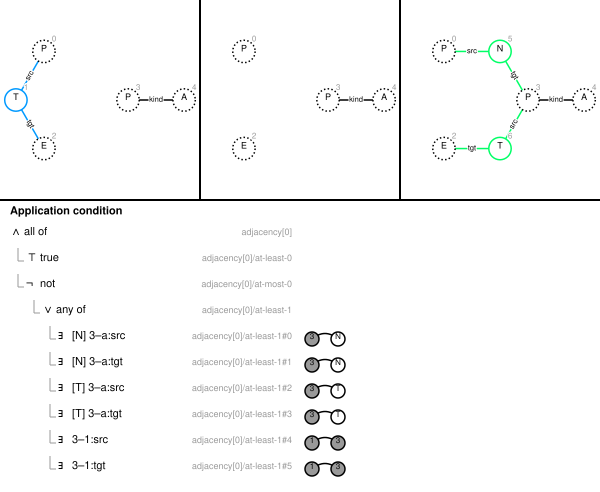

In [2]:
from mfobs import ModelInputs, ABA
MOTIFS = ("AB", "ABA", "ABBA", "AAAA", "ABABA")
backends = {motif: ABA.motif(motif, gated=False) for motif in MOTIFS}
defaults = {motif: backend.specification() for motif, backend in backends.items()}
Omega = defaults[MOTIFS[0]].omega
rules = defaults[MOTIFS[0]].rules
observables = {motif: model.observables for motif, model in defaults.items()}
inputs = {motif: ModelInputs(Omega, rules, observables[motif]) for motif in MOTIFS}
rule_gmls = inputs[MOTIFS[0]].rule_gmls()
visual.rules([("insert_A", rule_gmls["insert_A"])])
files.input_rules(rule_gmls)

<h2 id="inputs" style="background:#fbe9e9;padding:12px 16px;border-radius:5px">2 · Inputs & semantics</h2>

Vary only the motif. Pattern and expansion budgets are 64; the linear dimension budget is 24.


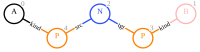

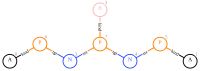

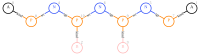

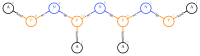

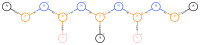

In [3]:
visual.rules([(name, gml) for model in inputs.values()
              for name, gml in model.query_gmls().items()], identity=True)

<h2 id="observables" style="background:#e8f0fb;padding:12px 16px;border-radius:5px">3 · Observable discovery</h2>

Run the two searches independently from the same rules and query.


**Algorithm 1 · Linear expectation closure**

In [4]:
linear = {motif: backends[motif].linear_closure(model, maximum_dimension=24)
          for motif, model in inputs.items()}

**Algorithm 2 · Pattern support and polynomial events**

In [5]:
results = {motif: backends[motif].jump_closure(
    model, support_pattern_limit=64, support_expansion_limit=64)
    for motif, model in inputs.items()}

In [6]:
for motif, result in results.items():
    result["linear"] = linear[motif]
visual.table([
    {"Query": motif, "Counts": ", ".join(r["support_discovery"]["patterns"]),
     "pJC": r["pjc"]["status"], "Linear closure": r["linear"]["status"]}
    for motif, r in results.items()
])
for motif, result in results.items():
    suite.gml_table(result["support_discovery"]["patterns"], motif + " · patterns")


,Query,Counts,pJC,Linear closure
0,AB,"C_AB, M_A, M_B, S_A",CLOSED,UNKNOWN_DIMENSION_LIMIT
1,ABA,"C_ABA, M_A, M_B, S_AB, S_A",CLOSED,UNKNOWN_DIMENSION_LIMIT
2,ABBA,"C_ABBA, M_A, M_B, S_ABB, S_AB, S_A",CLOSED,UNKNOWN_DIMENSION_LIMIT
3,AAAA,"C_AAAA, M_A, M_B, S_AAA, S_AA, S_A",CLOSED,UNKNOWN_DIMENSION_LIMIT
4,ABABA,"C_ABABA, M_A, M_B, S_ABAB, S_ABA, S_AB, S_A",CLOSED,UNKNOWN_DIMENSION_LIMIT


Count,Pattern,Meaning
C_AB,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22C_AB%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%204%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%204%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",selected query
M_A,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22A%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
M_B,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22B%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
S_A,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22T%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22E%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22A%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%207%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",generator image


Count,Pattern,Meaning
C_ABA,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22C_ABA%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%204%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%204%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%207%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%207%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",selected query
M_A,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22A%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
M_B,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22B%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
S_AB,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22T%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22E%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%209%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2010%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%2010%20label%20%22src%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",generator image
S_A,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22T%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22E%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22A%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%207%20label%20%22kin

Count,Pattern,Meaning
C_ABBA,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22C_ABBA%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%204%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%204%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%207%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%207%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%2010%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%209%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%2010%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",selected query
M_A,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22A%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
M_B,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22B%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
S_ABB,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22T%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22E%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%2011%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%2012%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%2013%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2012%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2013%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%2011%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%209%20target%2010%20label%20%2

Count,Pattern,Meaning
C_AAAA,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22C_AAAA%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%204%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%204%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%207%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%207%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%2010%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%209%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%2010%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",selected query
M_A,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22A%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
M_B,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22B%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
S_AAA,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22T%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22E%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%2011%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%2012%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%2013%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2012%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2013%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%2011%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%209%20target%2010%20label%20%2

Count,Pattern,Meaning
C_ABABA,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22C_ABABA%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%2011%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%2012%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%2013%20label%20%22N%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%204%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%204%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%207%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%207%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%2010%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%209%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%2010%20label%20%22tgt%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%2013%20label%20%22src%22%20%5D%0A%09%09edge%20%5B%20source%2011%20target%2012%20label%20%22kind%22%20%5D%0A%09%09edge%20%5B%20source%2011%20target%2013%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",selected query
M_A,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22A%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
M_B,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%203%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22B%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22kind%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%203%0A%09%09op%20%22%3D%22%0A%09%09count%200%0A%09%09nodeLabels%20%5B%20label%20%22N%22%20label%20%22T%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22src%22%20label%20%22tgt%22%20%5D%0A%09%5D%0A%5D&drawMode=circles&withEdgeLabels=on&drawRuleConditions=on"" target=""_blank"" rel=""noopener"">View in MolFoundry",rule activity
S_ABAB,"<a href=""https://molfoundry.de/depiction?gml=rule%20%5B%0A%09ruleID%20%22pattern%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22T%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22E%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%2011%20label%20%22B%22%20%5D%0A%09%09node%20%5B%20id%2012%20label%20%22N%22%20%5D%0A%09%09node%20%5B%20id%2013%20label%20%22P%22%20%5D%0A%09%09node%20%5B%20id%2014%20label%20%22A%22%20%5D%0A%09%09node%20%5B%20id%2015%20label%20%22N%22%20%5D%0A

<h2 id="ode" style="background:#f0eafb;padding:12px 16px;border-radius:5px">4 · Generator identities</h2>

Each row uses its own generated query drift and event model.

In [7]:
for motif,r in results.items():
    print(motif)
    view.show_equations(r, names=r["support_discovery"]["selected_queries"])

AB


<IPython.core.display.Math object>

ABA


<IPython.core.display.Math object>

ABBA


<IPython.core.display.Math object>

AAAA


<IPython.core.display.Math object>

ABABA


<IPython.core.display.Math object>

[← All examples](../paper_examples.ipynb)